In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
path = "/home/joyvillalobos/proyectos/qa_investigation/data/datos.csv"
df = pd.read_csv(path)

In [3]:
df.head()

,error_id,detection_date,review_date,days_to_detection,reviewer_id,reviewer_shift,reviewer_tenure_months,reviewer_qa_score,marketplace,product_category,...,root_cause,severity,detection_source,resolution_time_hours,rework_cost_usd,product_live_when_detected,customer_impact,escalated_to_compliance,corrective_action_completed,is_repeat_error
0,ERR-0001,2026-04-13,2026-03-21,23,R10,Morning,4,80.4,US,Home & Kitchen,...,Time Pressure,Critical,Customer Complaint,107.3,1501.29,True,True,True,True,False
1,ERR-0002,2026-04-15,2026-04-10,5,R07,Night,9,82.8,US,Health & Personal Care,...,Fatigue,High,Peer Review,34.5,520.44,True,True,False,True,False
2,ERR-0003,2026-04-15,2026-03-21,25,R12,Night,2,74.7,MX,Baby Products,...,Training Gap,Critical,Customer Complaint,166.1,3521.25,True,True,False,True,False
3,ERR-0004,2026-04-18,2026-04-17,1,R06,Night,11,78.7,CA,Home & Kitchen,...,Fatigue,Medium,Peer Review,52.6,60.16,False,False,True,True,False
4,ERR-0005,2026-04-21,2026-04-20,1,R06,Night,11,78.7,US,Beauty,...,Seller Document Ambiguity,High,Peer Review,61.3,662.18,True,True,True,True,False


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   error_id                     150 non-null    str    
 1   detection_date               150 non-null    str    
 2   review_date                  150 non-null    str    
 3   days_to_detection            150 non-null    int64  
 4   reviewer_id                  150 non-null    str    
 5   reviewer_shift               150 non-null    str    
 6   reviewer_tenure_months       150 non-null    int64  
 7   reviewer_qa_score            150 non-null    float64
 8   marketplace                  150 non-null    str    
 9   product_category             150 non-null    str    
 10  document_type                150 non-null    str    
 11  compliance_standard          150 non-null    str    
 12  seller_tier                  150 non-null    str    
 13  documents_in_case            15

In [5]:
df.root_cause.unique()

<ArrowStringArray>
[            'Time Pressure',                   'Fatigue',
              'Training Gap', 'Seller Document Ambiguity',
        'Unclear Guidelines',                'Tool Issue']
Length: 6, dtype: str

In [6]:
df[df.root_cause == 'Seller Document Ambiguity']

,error_id,detection_date,review_date,days_to_detection,reviewer_id,reviewer_shift,reviewer_tenure_months,reviewer_qa_score,marketplace,product_category,...,root_cause,severity,detection_source,resolution_time_hours,rework_cost_usd,product_live_when_detected,customer_impact,escalated_to_compliance,corrective_action_completed,is_repeat_error
4,ERR-0005,2026-04-21,2026-04-20,1,R06,Night,11,78.7,US,Beauty,...,Seller Document Ambiguity,High,Peer Review,61.3,662.18,True,True,True,True,False
9,ERR-0010,2026-05-07,2026-04-15,22,R08,Afternoon,7,80.7,US,Home & Kitchen,...,Seller Document Ambiguity,Low,Internal Audit,8.8,49.18,True,True,False,True,False
20,ERR-0021,2026-06-01,2026-05-10,22,R04,Afternoon,18,88.5,US,Home & Kitchen,...,Seller Document Ambiguity,Low,Seller Appeal,7.8,17.34,False,False,False,False,False
23,ERR-0024,2026-06-08,2026-05-12,27,R12,Night,2,80.6,CA,Beauty,...,Seller Document Ambiguity,Low,Seller Appeal,7.2,18.78,False,False,False,True,False
28,ERR-0029,2026-06-11,2026-06-01,10,R02,Morning,28,95.0,US,Home & Kitchen,...,Seller Document Ambiguity,Low,Seller Appeal,11.5,36.99,False,False,False,False,False
31,ERR-0032,2026-06-23,2026-06-17,6,R05,Morning,14,82.3,FR,Toys & Games,...,Seller Document Ambiguity,Critical,Peer Review,220.4,1409.69,False,False,True,True,False
33,ERR-0034,2026-06-23,2026-06-17,6,R01,Morning,36,93.4,DE,Pet Supplies,...,Seller Document Ambiguity,High,Internal Audit,87.2,151.79,False,False,True,True,True
36,ERR-0037,2026-06-28,2026-06-23,5,R09,Night,5,80.9,FR,Toys & Games,...,Seller Document Ambiguity,Low,Peer Review,5.9,32.39,True,False,False,True,True
37,ERR-0038,2026-07-01,2026-05-09,53,R02,Morning,28,97.7,FR,Beauty,...,Seller Document Ambiguity,Medium,Regulatory Notice,41.0,86.86,True,False,True,True,False
48,ERR-0049,2026-07-08,2026-06-29,9,R11,Night,3,87.4,US,Pet Supplies,...,Seller Document Ambiguity,Low,Internal Audit,11.9,25.94,True,False,False,True,False


In [9]:
rework_cost_reviewer = df.groupby('reviewer_id')['rework_cost_usd'].sum().sort_values(ascending=False).head(10)
print(rework_cost_reviewer)

reviewer_id
R10    10118.14
R12     9909.48
R07     9678.28
R09     7556.26
R06     6346.67
R05     5385.02
R02     4229.39
R08     4125.07
R11     2514.01
R04     1363.98
Name: rework_cost_usd, dtype: float64


<Axes: xlabel='reviewer_id'>

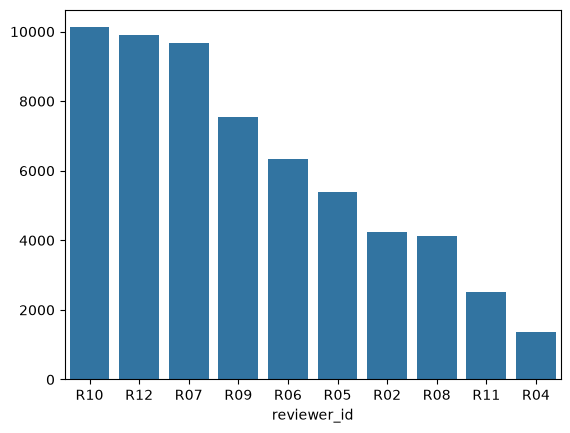

In [11]:
sns.barplot(x=rework_cost_reviewer.index, y=rework_cost_reviewer.values)